# RuO₂/TiO₂: gradually reducing film crystallinity

Adapted from [RuO2_TiO2_CTR_DWBA.ipynb](RuO2_TiO2_CTR_DWBA.ipynb), using the same
`RuO2_TiO2_Poisson_etching.xtal` model at **20 keV**: TiO₂ bulk, graded epitaxy
interface, RuO₂ film, and an etched Poisson surface. No experimental data are needed.

The top surface is made smoother by reducing the Poisson roughening fraction
from $\alpha=1$ to **$\alpha=0.1$**, while keeping $W=-6$ structural layers
and offset zero. The mean etched thickness is unchanged. For this step–Poisson
distribution the surface-height standard deviation drops from $\sqrt{6}\approx2.45$
to $\sqrt{0.6+0.4(1-0.4)}\approx0.92$ structural layers. The graded interface
is retained; this smoother geometry is held fixed throughout the crystallinity sweep.

We sweep the coherent amplitude fraction $c=1,0.8,0.6,0.4,0.2,0$ while retaining
all layer positions, occupancies, roughness, thicknesses, and optical constants.
By default, **all RuO₂ source cells** share this sweep: the Film cell, the upper
interface cell, and the exposed surface termination cells. TiO₂ remains fully
crystalline. Set `vary_interface_and_surface = False` below to vary only the Film
source cell; the interface and exposed surface will then remain crystalline.

For each affected material record,
$$
\rho(c)=\bar\rho+c(\rho_{\mathrm{at}}-\bar\rho),\qquad
F_{\mathrm{DWBA}}(c)=c(F_{\mathrm{atomic}}^{(1)}-F_{\mathrm{reference}}),
\qquad F_{\mathrm{kin}}(c)=cF_{\mathrm{kin}}(1).
$$
The reference $n_0(z)$ and its wavefields stay fixed. An isolated contribution's
intensity scales as $c^2$, but the **total** intensity need not decrease at every
point because the film interferes with the substrate. At $c=0$ the material
still refracts and absorbs; this is not a bare-substrate calculation or a model
of redistributed diffuse scattering.

Run all cells from the repository root or this notebook's directory. Plots use
the inline backend so their outputs are saved in the notebook.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np


def find_repository_root():
    '''Locate this checkout from the notebook directory or repository root.'''
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "orgui" / "datautils").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from within the orGUI checkout.")


repository_root = find_repository_root()
if "orgui" not in sys.modules:
    sys.path.insert(0, str(repository_root))

from orgui.datautils.xrayutils import CTRcalc, CTRfilm, CTRuc
from orgui.datautils.xrayutils.CTRoptics import homogeneous_bulk_profile

if not hasattr(CTRuc.UnitCell, "crystallinity"):
    raise RuntimeError("Use the orGUI version with UnitCell.crystallinity and restart the kernel.")
if not hasattr(CTRuc._CTRcalc_cpp, "unitcell_F_DWBA_records"):
    raise RuntimeError("DWBA requires the native CTR extension with record support.")

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.16,
})
print("Loaded CTRuc:", Path(CTRuc.__file__).resolve())

Loaded CTRuc: C:\Users\timof\Documents\repos\orGUI\orgui\datautils\xrayutils\CTRuc.py


## Choose the source cells

The material property is assigned to `UnitCell`, not to the crystal's component
weights. Generated additions inherit their own source crystallinity; negative
interface/etching records retain the crystallinity of the material they remove.
Thus making a surface slab noncrystalline still removes the crystalline Film
slab that it replaces.

In [2]:
crystallinities = np.array([1.0, 0.8, 0.6, 0.4, 0.2, 0.0])
vary_interface_and_surface = True
surface_alpha = 0.1  # 0: ideal layer-by-layer surface; 1: full Poisson roughening

model_path = repository_root / "examples/CTR/RuO2_TiO2_Poisson_etching.xtal"
crystal = CTRcalc.SXRDCrystal.fromFile(str(model_path))
crystal.apply_stacking()

film, = [component for component in crystal.uc_surface_list
         if isinstance(component, CTRfilm.Film)]
interface, = [component for component in crystal.uc_surface_list
              if isinstance(component, CTRfilm.EpitaxyInterface)]
surface, = [component for component in crystal.uc_surface_list
            if isinstance(component, CTRfilm.PoissonSurface)]

# Smooth the top surface without changing the mean height change W + offset.
surface.basis[1] = surface_alpha
surface.basis_0[1] = surface_alpha
surface.profile = CTRfilm.PoissonProfile(
    mean_change=surface.basis[0], alpha=surface_alpha, offset=surface.basis[2],
    tail_probability=surface.profile.tail_probability,
)
crystal.apply_stacking()

surface_cells = (list(surface.termination_cells.values())
                 if surface.termination_cells else [surface.unitcell])
ruo2_sources = [film.unitcell, interface.uc_top, *surface_cells]
tio2_sources = [crystal.uc_bulk, interface.uc_bottom]
assert all("Ru" in cell.names for cell in ruo2_sources)
assert all("Ti" in cell.names for cell in tio2_sources)
assert not {id(cell) for cell in ruo2_sources} & {id(cell) for cell in tio2_sources}
for cell in ruo2_sources + tio2_sources:
    cell.crystallinity = 1.0

varied_sources = ruo2_sources if vary_interface_and_surface else [film.unitcell]
# A shared source is assigned once even if used by several components.
varied_sources = list({id(cell): cell for cell in varied_sources}.values())


def set_film_crystallinity(value):
    '''Set the selected RuO₂ source cells' dimensionless order in [0, 1].'''
    for cell in varied_sources:
        cell.crystallinity = value


bulk_profile = homogeneous_bulk_profile(crystal.uc_bulk)
alpha_c = np.sqrt(2.0 * float(bulk_profile.values[0, 1]))
alpha_i_fixed = 1.5 * alpha_c
print(f"Energy: {crystal.uc_bulk._E * 1e-3:g} keV")
print(f"Film nominal width: {film.basis[0]:g} structural layers")
print(f"Poisson W, alpha, offset: {surface.basis}")
print(f"TiO₂ critical angle: {np.rad2deg(alpha_c):.5f} deg")
print(f"(0, 1, L) incidence: {np.rad2deg(alpha_i_fixed):.5f} deg")
print("Swept source cells:", ", ".join(cell.name for cell in varied_sources))
print(f"Kinematic attenuation retained from the model: {crystal.atten:g}")

Energy: 20 keV
Film nominal width: 17 structural layers
Poisson W, alpha, offset: [-6.   0.1  0. ]
TiO₂ critical angle: 0.11601 deg
(0, 1, L) incidence: 0.17402 deg
Swept source cells: RuO2, RuO2interf, RuO2_termination_1, RuO2_termination_2
Kinematic attenuation retained from the model: 0.01


## Prepare the wavefields once, then sweep crystallinity

We retain the reference example's geometries: equal angles for $(0,0,L)$ and
fixed incidence $\alpha_i=1.5\alpha_c$ for $(0,1,L)$. Angles are passed internally
in radians; $L$ is in reference-cell r.l.u. A denser low-$L$ specular grid resolves
the critical-angle region.

Specular `F_effective` is the **total field** $r_0+r_{\mathbf h}$ converted to
electron units. Off specular, `F_h` is the coherent contrast and $r_0=0$.
`reflectivity` is $|r_0+r_{\mathbf h}|^2$. The kinematic curve retains the model's
empirical attenuation; DWBA uses its default physical absorption without an
additional bulk attenuation term.

In [3]:
L_specular = np.unique(np.r_[np.linspace(0.004, 0.4, 501),
                            np.linspace(0.4, 7.0, 1801)])
L_rod = np.linspace(0.06, 6.0, 1801)

crystal.dwba.set_ctr_geometry(equal_angles=True, rods=[(0.0, 0.0)])
crystal.dwba.set_ctr_geometry(alpha_i=alpha_i_fixed, rods=[(0.0, 1.0)])
prepared_specular = crystal.dwba.prepare(0.0, 0.0, L_specular)
prepared_rod = crystal.dwba.prepare(0.0, 1.0, L_rod)
assert np.all(prepared_specular.is_specular)
assert not np.any(prepared_rod.is_specular)
assert np.all(prepared_rod.alpha_f > 0.0)

optical_profile_initial = crystal.optical_profile().copy()
optical_profiles = []
results = {}
for value in crystallinities:
    set_film_crystallinity(float(value))
    specular = crystal.dwba.evaluate_prepared(prepared_specular)
    rod = crystal.dwba.evaluate_prepared(prepared_rod)
    kinematic = crystal.evaluate_kinematic(0.0, 1.0, L_rod)
    film_dwba = sum((item.F_h for item in rod.contributions
                     if item.component_name == film.name), start=np.zeros_like(rod.F_h))
    film_kinematic, = [item.amplitude for item in kinematic.components
                       if item.name == film.name]
    for amplitude in [specular.F_effective, rod.F_h, kinematic.total,
                      film_dwba, film_kinematic]:
        assert np.all(np.isfinite(amplitude))
    results[float(value)] = {
        "specular": specular, "rod": rod, "kinematic": kinematic.total,
        "film_dwba": film_dwba, "film_kinematic": film_kinematic,
    }
    optical_profiles.append(crystal.optical_profile().copy())
    np.testing.assert_array_equal(optical_profiles[-1], optical_profile_initial)
    np.testing.assert_array_equal(rod.F_reference, 0.0j)
    print(f"Evaluated c = {value:.1f}; optical profile unchanged")

set_film_crystallinity(1.0)
colors = plt.colormaps["viridis"](np.linspace(0.08, 0.9, len(crystallinities)))
legend_handles = [Line2D([0], [0], color=color, lw=2, label=f"c = {value:.1f}")
                  for value, color in zip(crystallinities, colors)]

Evaluated c = 1.0; optical profile unchanged


Evaluated c = 0.8; optical profile unchanged


Evaluated c = 0.6; optical profile unchanged


Evaluated c = 0.4; optical profile unchanged


Evaluated c = 0.2; optical profile unchanged


Evaluated c = 0.0; optical profile unchanged


## What changes in the measured rods?

All curves use the same scale; no curve is normalized to its own maximum.
The bottom-left panel shows the fixed optical reflection as a dashed line.
The $c=0$ sample can differ from that line because **TiO₂ still has atomic
contrast**, including the interface's TiO₂ additions and removals. In the
film-only mode, the unchanged crystalline RuO₂ interface and surface also remain.

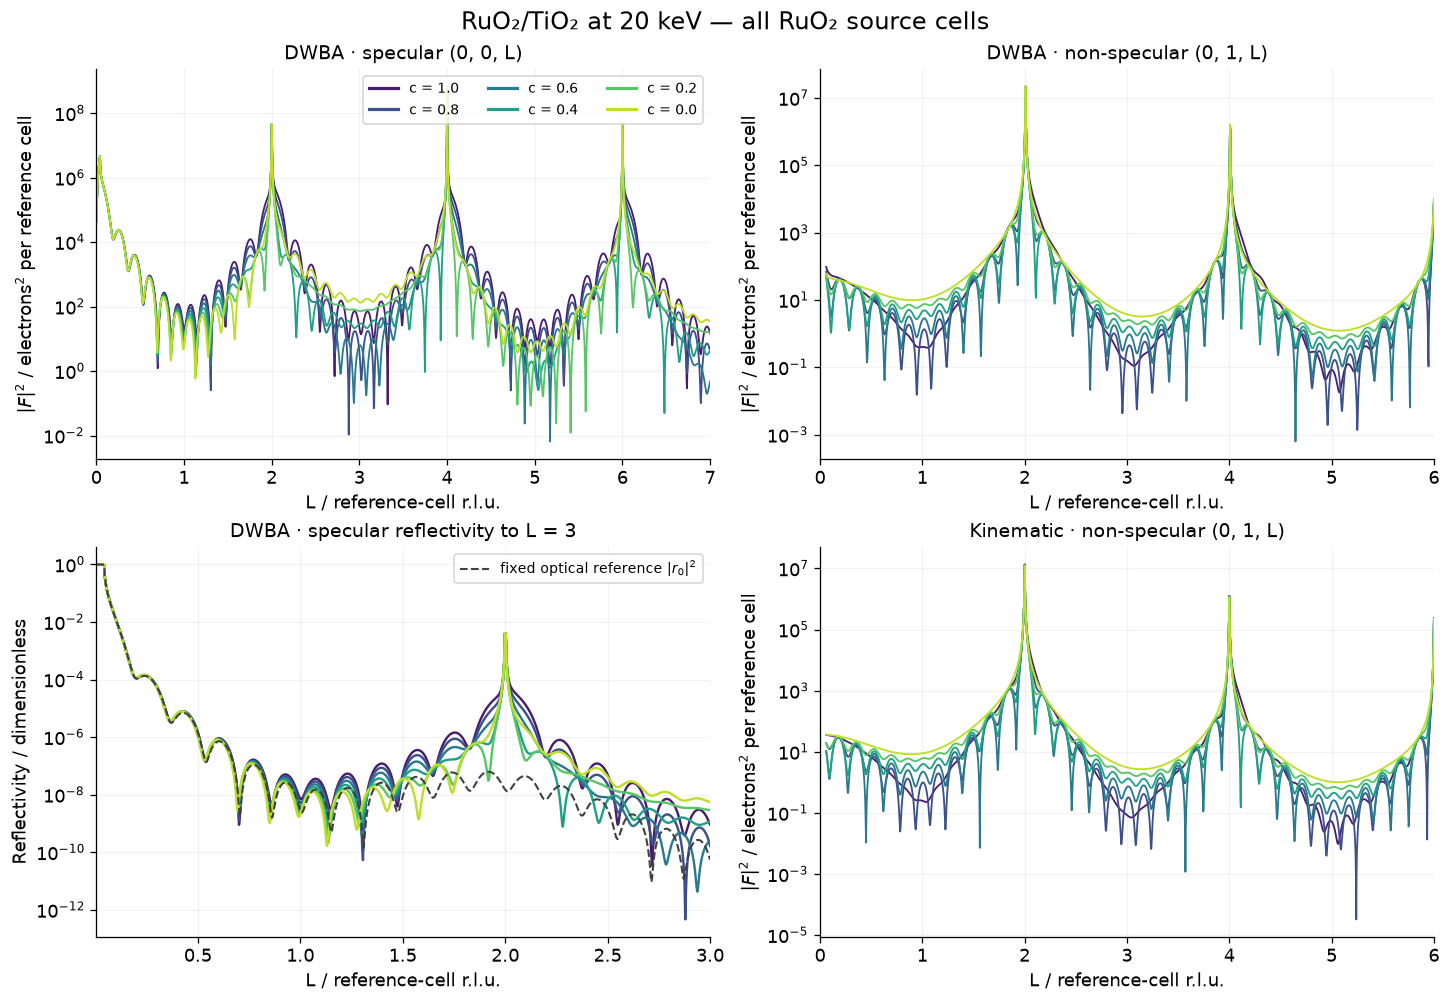

In [4]:
figure_rods, axes = plt.subplots(2, 2, figsize=(12.5, 8.6), layout="constrained")
reflectivity_mask = L_specular <= 3.0
for value, color in zip(crystallinities, colors):
    item = results[float(value)]
    axes[0, 0].semilogy(L_specular, np.abs(item["specular"].F_effective)**2,
                        color=color, lw=1.15)
    axes[0, 1].semilogy(L_rod, np.abs(item["rod"].F_h)**2, color=color, lw=1.15)
    axes[1, 0].semilogy(L_specular[reflectivity_mask], item["specular"].reflectivity[reflectivity_mask],
                        color=color, lw=1.5)
    axes[1, 1].semilogy(L_rod, np.abs(item["kinematic"])**2, color=color, lw=1.15)

reference_R = np.abs(results[1.0]["specular"].unperturbed_amplitude)**2
axes[1, 0].semilogy(L_specular[reflectivity_mask], reference_R[reflectivity_mask], "--", color="0.25",
                    lw=1.3, label=r"fixed optical reference $|r_0|^2$")
axes[1, 0].legend(fontsize=9)
titles = ["DWBA · specular (0, 0, L)", "DWBA · non-specular (0, 1, L)",
          "DWBA · specular reflectivity to L = 3", "Kinematic · non-specular (0, 1, L)"]
for ax, title in zip(axes.flat, titles):
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("L / reference-cell r.l.u.")
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.set_ylabel(r"$|F|^2$ / electrons$^2$ per reference cell")
axes[1, 0].set_ylabel("Reflectivity / dimensionless")
axes[0, 0].set_xlim(0.0, 7.0)
axes[0, 1].set_xlim(0.0, 6.0)
axes[1, 0].set_xlim(L_specular[0], 3.0)
axes[1, 1].set_xlim(0.0, 6.0)
scope = "all RuO₂ source cells" if vary_interface_and_surface else "Film cell only"
figure_rods.suptitle(f"RuO₂/TiO₂ at 20 keV — {scope}", fontsize=15)
axes[0, 0].legend(handles=legend_handles, ncol=3, fontsize=9, loc="upper right")
plt.show()

## The optical stack is unchanged

Every sweep point was checked against the initial optical profile with exact
array equality. The reference indices and wavefields in the two preparations
are reused. The plots below sample the prepared piecewise-constant profile
(including its explicit boundaries), using dimensionless $\delta$ and $\beta$
shown in units of $10^{-6}$.
The overlapping curves are intentional.

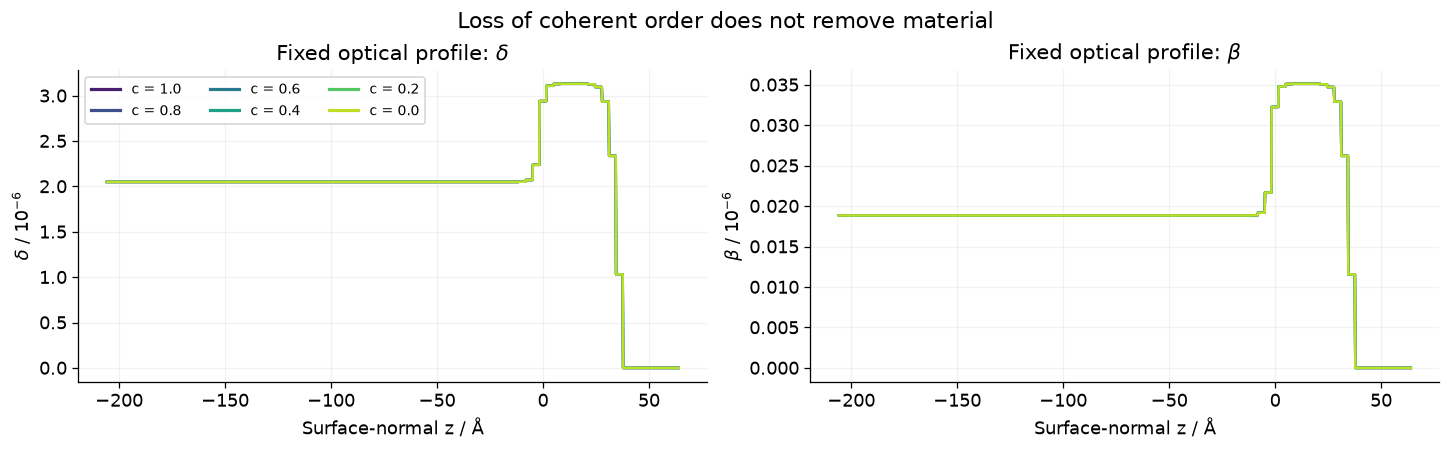

Maximum optical-profile change: 0.0


In [5]:
profile = prepared_specular.reference.profile
boundaries = profile.boundaries
z = np.linspace(boundaries[0] - 10.0, boundaries[-1] + 10.0, 1801)
medium = np.searchsorted(boundaries, z, side="right")
figure_optics, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), layout="constrained")
for value, color in zip(crystallinities, colors):
    # Same immutable reference for every c; draw all curves to show overlap.
    for ax, column in zip(axes, [1, 2]):
        ax.plot(z, profile.values[medium, column] * 1e6, color=color, lw=1.5)
for ax, symbol in zip(axes, [r"$\delta$", r"$\beta$"]):
    ax.set_xlabel("Surface-normal z / Å")
    ax.set_ylabel(symbol + r" / $10^{-6}$")
    ax.set_title("Fixed optical profile: " + symbol)
axes[0].legend(handles=legend_handles, ncol=3, fontsize=9)
figure_optics.suptitle("Loss of coherent order does not remove material", fontsize=14)
plt.show()
print("Maximum optical-profile change:",
      max(np.max(np.abs(profile - optical_profile_initial)) for profile in optical_profiles))

## Isolate the Film contribution: amplitude $\propto c$, intensity $\propto c^2$

The Film component alone has no fixed substrate term. Its complex amplitude
must therefore scale exactly with $c$ in both DWBA and the kinematic model.
The left panel shows its DWBA rod intensity on a linear scale so the zero-order
curve is visible. The right panel compares the squared amplitude norm over the
sampled rod, normalized to $c=1$, with $c^2$; this is a numerical diagnostic,
not an experimentally integrated intensity.

The assertions also verify the total-amplitude interpolation
$F(c)=F(0)+c[F(1)-F(0)]$ and the invariant specular reference reflection.

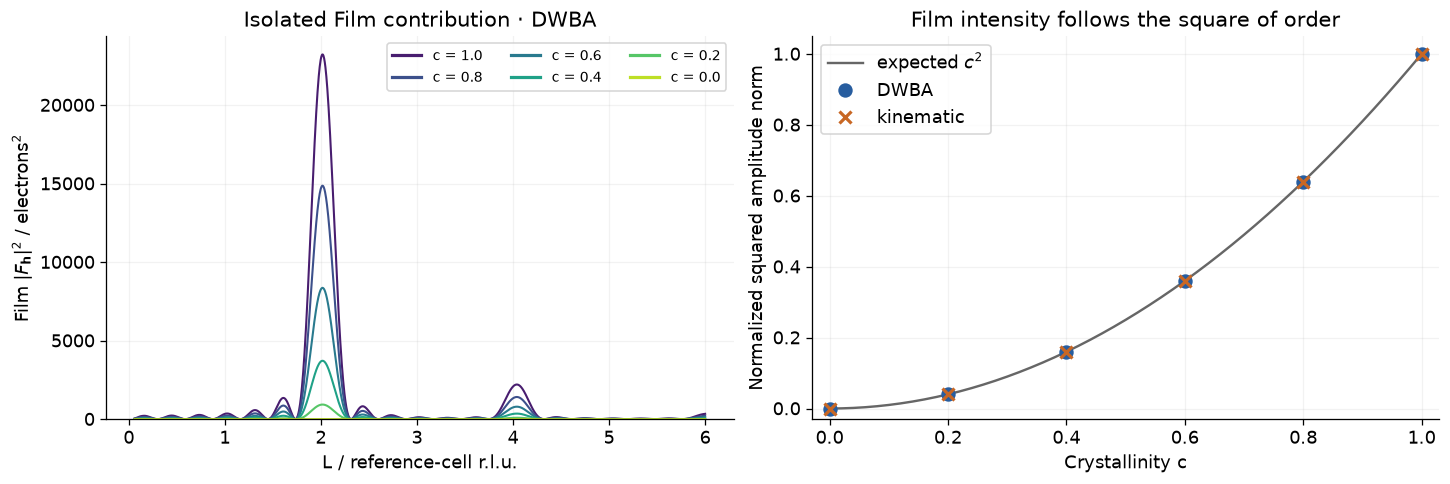

All checks passed: fixed optics, linear contrast, c² isolated intensity.


In [6]:
for value in crystallinities:
    item = results[float(value)]
    for key in ["film_dwba", "film_kinematic"]:
        baseline = results[1.0][key]
        tolerance = 2e-12 * max(1.0, np.max(np.abs(baseline)))
        np.testing.assert_allclose(item[key], value * baseline, rtol=2e-11, atol=tolerance)
    for key, attribute in [("specular", "total_amplitude"), ("rod", "F_h")]:
        endpoint_zero = getattr(results[0.0][key], attribute)
        endpoint_one = getattr(results[1.0][key], attribute)
        expected = endpoint_zero + value * (endpoint_one - endpoint_zero)
        np.testing.assert_allclose(getattr(item[key], attribute), expected,
                                   rtol=2e-10, atol=2e-12 * max(1., np.max(np.abs(expected))))
    np.testing.assert_array_equal(item["specular"].unperturbed_amplitude,
                                  results[1.0]["specular"].unperturbed_amplitude)

np.testing.assert_array_equal(results[0.0]["film_dwba"], 0.0j)
np.testing.assert_array_equal(results[0.0]["film_kinematic"], 0.0j)
norms = {}
for key in ["film_dwba", "film_kinematic"]:
    denominator = np.sum(np.abs(results[1.0][key])**2)
    norms[key] = np.array([np.sum(np.abs(results[float(c)][key])**2) / denominator
                           for c in crystallinities])
    np.testing.assert_allclose(norms[key], crystallinities**2, atol=2e-12)

figure_scaling, axes = plt.subplots(1, 2, figsize=(12.5, 4.1), layout="constrained")
for value, color in zip(crystallinities, colors):
    axes[0].plot(L_rod, np.abs(results[float(value)]["film_dwba"])**2,
                 color=color, lw=1.3)
axes[0].set(xlabel="L / reference-cell r.l.u.",
            ylabel=r"Film $|F_{\mathbf{h}}|^2$ / electrons$^2$",
            title="Isolated Film contribution · DWBA")
axes[0].set_ylim(bottom=0.0)
axes[0].legend(handles=legend_handles, ncol=3, fontsize=9)
c_dense = np.linspace(0., 1., 201)
axes[1].plot(c_dense, c_dense**2, "-", color="0.4", label=r"expected $c^2$")
axes[1].plot(crystallinities, norms["film_dwba"], "o", color="#275d9f",
             ms=8, label="DWBA")
axes[1].plot(crystallinities, norms["film_kinematic"], "x", color="#c86724",
             ms=8, mew=2, label="kinematic")
axes[1].set(xlabel="Crystallinity c", ylabel="Normalized squared amplitude norm",
            title="Film intensity follows the square of order", xlim=(-0.03, 1.03),
            ylim=(-0.03, 1.05))
axes[1].legend()
plt.show()
print("All checks passed: fixed optics, linear contrast, c² isolated intensity.")

## Try a different sweep or fit crystallinity

- Edit `surface_alpha` to change the surface smoothness (0 is ideal layer-by-layer,
  1 is the original Poisson roughness), then rerun the model and following cells.
- Edit `crystallinities` in the model cell; retain the endpoints 1 and 0 for the
  diagnostic assertions, then rerun the cells below it.
- Set `vary_interface_and_surface = False` and rerun to keep the RuO₂ interface
  and exposed slabs crystalline while changing only the Film material.
- Set separate values on `film.unitcell`, `interface.uc_top`, and individual
  `surface.termination_cells` to explore different regional order.
- To fit the Film's order independently, use
  `film.unitcell.addCrystallinityParameter(name="film_order", limits=(0, 1))`.
  This registers one source cell; it does not automatically tie independently
  stored interface or surface fit parameters together.

The live crystal has been reset to $c=1$ after the sweep; `results` keeps every
evaluated state. The original model file and original example notebook are
unchanged.